# Experiment 1 — GHZ state and Mermin operator (ibm_marrakesh)

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

theta = Parameter("θ")
phases = np.linspace(0, 2*np.pi, 11)
individual_phases = [[ph] for ph in phases]

pm = generate_preset_pass_manager(optimization_level=1, backend=backend)

qc_base = QuantumCircuit(2)
qc_base.h(0)
qc_base.cx(0, 1)
qc_base.ry(theta, 0)
isa_base = pm.run(qc_base)

obs1 = SparsePauliOp(["ZZ", "ZX", "XZ", "XX"], coeffs=[1, -1, 1, 1])
obs2 = SparsePauliOp(["ZZ", "ZX", "XZ", "XX"], coeffs=[1, 1, -1, 1])
isa_obs1 = obs1.apply_layout(isa_base.layout)
isa_obs2 = obs2.apply_layout(isa_base.layout)

estimator = Estimator(mode=backend)
pub_base = (isa_base, [[isa_obs1], [isa_obs2]], individual_phases)
job_base = estimator.run(pubs=[pub_base], precision=0.05)
print("Job Base ID:", job_base.job_id())

qr = QuantumRegister(8, 'q')
cr_mid = ClassicalRegister(1, 'mid')
cr_final = ClassicalRegister(2, 'c')
qc_caida = QuantumCircuit(qr, cr_mid, cr_final)

qc_caida.h(0)
for i in range(1, 7):
    qc_caida.cx(0, i)

qc_caida.h(7)
qc_caida.cx(7, 1)

qc_caida.ry(theta, 0)

qc_caida.measure(7, cr_mid[0])

with qc_caida.if_test((cr_mid, True)):
    qc_caida.ry(np.pi/16, 1)

qc_caida.measure([0, 1], cr_final)

isa_caida = pm.run(qc_caida)

sampler = Sampler(mode=backend)
pub_caida = (isa_caida, individual_phases, 1024)
job_caida = sampler.run([pub_caida])
print("Job Caída ID:", job_caida.job_id())

print("Jobs enviados. Cuando ambos DONE, ejecuta la celda de resultados.")


Backend: ibm_marrakesh


~/opt/miniconda3/envs/qiskit_env_2.0/lib/python3.10/site-packages/qiskit_ibm_runtime/qiskit_runtime_service.py:1210: UserWarning: This instance has met its usage limit. Workloads will not run until time is made available. Check https://quantum.cloud.ibm.com/instances/crn%3Av1%3Abluemix%3Apublic%3Aquantum-computing%3Aus-east%3Aa%2Fefeb08916ca34a7695216c29668a2406%3Aafb28708-d872-41e1-82bd-f278cd568e43%3A%3A for more details.
  warnings.warn(


Job Base ID: d77c69ak86tc739u081g
Job Caída ID: d77c69qk86tc739u0830
Jobs enviados. Cuando ambos DONE, ejecuta la celda de resultados.


In [ ]:
from qiskit.quantum_info import partial_trace, entropy
import numpy as np
import matplotlib.pyplot as plt

result_base = job_base.result()
evs = result_base[0].data.evs
chsh1_base = evs[0, :] if evs.shape == (2, 11) else evs.T[0, :]
chsh2_base = evs[1, :] if evs.shape == (2, 11) else evs.T[1, :]

result_caida = job_caida.result()
bit_array = result_caida[0].data.c
chsh1_caida = []
chsh2_caida = []
entropia_externa = []

for i in range(11):
    counts = bit_array.get_counts(i)
    total = sum(counts.values())
    p00 = counts.get('00', 0)/total
    p01 = counts.get('01', 0)/total
    p10 = counts.get('10', 0)/total
    p11 = counts.get('11', 0)/total

    zz = p00 + p11 - p01 - p10
    zx = p00 - p11 - p01 + p10
    xz = p00 - p11 + p01 - p10
    xx = p00 + p11 + p01 + p10

    chsh1_caida.append(zz - zx + xz + xx)
    chsh2_caida.append(zz + zx - xz + xx)

    rho_ext = np.array([[p00 + p01, 0], [0, p10 + p11]])
    S_ext = entropy(rho_ext, base=2)
    entropia_externa.append(S_ext)

plt.figure(figsize=(12, 7))
plt.plot(phases/np.pi, chsh1_base, 'o-', color='blue', label='CHSH1 Base')
plt.plot(phases/np.pi, chsh2_base, 'o-', color='blue')
plt.plot(phases/np.pi, chsh1_caida, 's--', color='red', label='CHSH1 Con Caída')
plt.plot(phases/np.pi, chsh2_caida, 's--', color='red')
plt.axhline(2, color='gray', ls='--')
plt.axhline(2*np.sqrt(2), color='green', ls='-.')
plt.xlabel('θ / π')
plt.ylabel('Valor CHSH')
plt.title('Comparación: Base vs Caída con 6 qubits en el interior del BH')
plt.legend()
plt.grid(True)
plt.show()

print(f"Máximo Base (sin caída): {max(max(chsh1_base), max(chsh2_base)):.3f}")
print(f"Máximo Con Caída: {max(max(chsh1_caida), max(chsh2_caida)):.3f}")
print(f"Entropía reducida promedio del externo después de caída: {np.mean(entropia_externa):.3f}")


In [3]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_kingston')
print("Backend:", backend.name)

theta = Parameter("θ")
phases = np.linspace(0, 2*np.pi, 11)
individual_phases = [[ph] for ph in phases]

pm = generate_preset_pass_manager(optimization_level=1, backend=backend)

qc_base = QuantumCircuit(3)
qc_base.h(0)
qc_base.ry(theta, 0)
qc_base.cx(0, 1)
qc_base.cx(0, 2)

isa_base = pm.run(qc_base)

mermin = SparsePauliOp(["XXY", "XYX", "YXX", "YYY"], coeffs=[1, 1, 1, -1])
isa_mermin = mermin.apply_layout(isa_base.layout)

estimator = Estimator(mode=backend)
pub_base = (isa_base, [isa_mermin], individual_phases)
job_base = estimator.run(pubs=[pub_base], precision=0.05)
print("Job Base GHZ ID:", job_base.job_id())

qc_cut1 = QuantumCircuit(3, 3)
qc_cut1.h(0)
qc_cut1.ry(theta, 0)
qc_cut1.cx(0, 1)
qc_cut1.cx(0, 2)
qc_cut1.measure([0, 1, 2], [0, 1, 2])

isa_cut1 = pm.run(qc_cut1)

sampler = Sampler(mode=backend)
pub_cut1 = (isa_cut1, individual_phases, 1024)
job_cut1 = sampler.run([pub_cut1])
print("Job Corte 1 qubit ID:", job_cut1.job_id())

print("Jobs enviados. Cuando DONE, ejecuta la celda de resultados.")


Backend: ibm_kingston
Job Base GHZ ID: d7fdvuq1u7fs739lspu0
Job Corte 1 qubit ID: d7fdvve2cugc739qf4og
Jobs enviados. Cuando DONE, ejecuta la celda de resultados.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

result_base = job_base.result()
mermin_values = result_base[0].data.evs.flatten()

result_cut1 = job_cut1.result()
bit_array = result_cut1[0].data.c
correlacion_12 = []

for i in range(11):
    counts = bit_array.get_counts(i)
    total = sum(counts.values())
    p000 = counts.get('000', 0) / total
    p001 = counts.get('001', 0) / total
    p010 = counts.get('010', 0) / total
    p011 = counts.get('011', 0) / total
    p100 = counts.get('100', 0) / total
    p101 = counts.get('101', 0) / total
    p110 = counts.get('110', 0) / total
    p111 = counts.get('111', 0) / total

    czz_12 = abs((p000 + p100 + p011 + p111) - (p001 + p101 + p010 + p110))
    correlacion_12.append(czz_12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('ER = EPR: Estado GHZ de 3 qubits como Wormhole Tripartito\n'
             'IBM Marrakesh — Qiskit 2.x', fontsize=13)

plt.tight_layout()
plt.subplots_adjust(top=0.88)

ax1.plot(phases/np.pi, mermin_values, 'o-', color='blue')
ax1.axhline(2, color='gray', ls='--', label='Límite clásico')
ax1.axhline(4, color='green', ls='-.', label='Límite cuántico')
ax1.set_title('Wormhole abierto: Violación de Mermin')
ax1.set_xlabel('θ / π')
ax1.set_ylabel('Valor Mermin')
ax1.legend()
ax1.grid(True)

ax2.plot(phases/np.pi, correlacion_12, 's-', color='red')
ax2.axhline(0, color='gray', ls='--', label='Sin correlación')
ax2.axhline(1, color='green', ls='-.', label='Correlación máxima')
ax2.set_title('Wormhole cerrado: Correlación ZZ entre qubit 1 y 2')
ax2.set_xlabel('θ / π')
ax2.set_ylabel('Correlación ZZ')
ax2.legend()
ax2.grid(True)

plt.show()

print(f"Máximo violación de Mermin: {max(mermin_values):.3f}")
print(f"Correlación ZZ promedio después del corte: {np.mean(correlacion_12):.3f}")


In [1]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

theta = Parameter("θ")

phases = np.linspace(0, np.pi/2, 11)
individual_phases = [[ph] for ph in phases]

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

qc_base = QuantumCircuit(3)
qc_base.h(0)
qc_base.cx(0, 1)
qc_base.cx(0, 2)
qc_base.ry(theta, 0)

isa_base = pm.run(qc_base)

mermin = SparsePauliOp(["XXY", "XYX", "YXX", "YYY"], coeffs=[1, 1, 1, -1])
isa_mermin = mermin.apply_layout(isa_base.layout)

estimator = Estimator(mode=backend)
pub_base = (isa_base, [isa_mermin], individual_phases)
job_base = estimator.run(pubs=[pub_base], precision=0.03)
print("Job Base GHZ ID:", job_base.job_id())

qc_cut1 = QuantumCircuit(3, 3)
qc_cut1.h(0)
qc_cut1.cx(0, 1)
qc_cut1.cx(0, 2)
qc_cut1.ry(theta, 0)
qc_cut1.measure([0, 1, 2], [0, 1, 2])

isa_cut1 = pm.run(qc_cut1)

sampler = Sampler(mode=backend)
pub_cut1 = (isa_cut1, individual_phases, 2048)
job_cut1 = sampler.run([pub_cut1])
print("Job Corte 1 qubit ID:", job_cut1.job_id())
print("Jobs enviados. Cuando DONE, ejecuta la celda de resultados.")


Backend: ibm_marrakesh
Job Base GHZ ID: d7fedgd6agrc738ij3dg
Job Corte 1 qubit ID: d7fedgi1u7fs739lt7ng
Jobs enviados. Cuando DONE, ejecuta la celda de resultados.


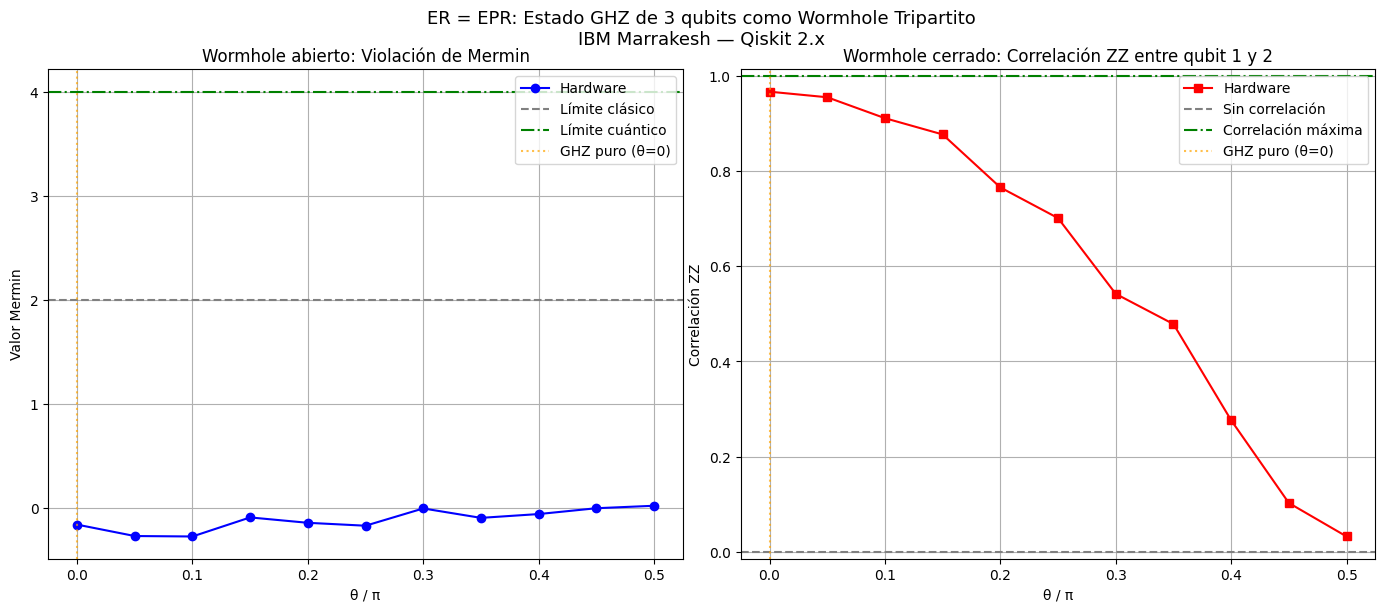

Máximo violación de Mermin: 0.017
Mermin en θ=0 (GHZ puro): -0.164
Correlación ZZ promedio: 0.601
Correlación ZZ en θ=0 (GHZ puro): 0.967


In [2]:
import numpy as np
import matplotlib.pyplot as plt

result_base = job_base.result()
mermin_values = result_base[0].data.evs.flatten()

result_cut1 = job_cut1.result()
bit_array = result_cut1[0].data.c

correlacion_12 = []
for i in range(11):
    counts = bit_array.get_counts(i)
    total = sum(counts.values())
    p000 = counts.get('000', 0) / total
    p001 = counts.get('001', 0) / total
    p010 = counts.get('010', 0) / total
    p011 = counts.get('011', 0) / total
    p100 = counts.get('100', 0) / total
    p101 = counts.get('101', 0) / total
    p110 = counts.get('110', 0) / total
    p111 = counts.get('111', 0) / total

    czz_12 = abs((p000 + p100 + p011 + p111) - (p001 + p101 + p010 + p110))
    correlacion_12.append(czz_12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('ER = EPR: Estado GHZ de 3 qubits como Wormhole Tripartito\n'
             'IBM Marrakesh — Qiskit 2.x', fontsize=13)
plt.tight_layout()
plt.subplots_adjust(top=0.88)

ax1.plot(phases/np.pi, mermin_values, 'o-', color='blue', label='Hardware')
ax1.axhline(2, color='gray', ls='--', label='Límite clásico')
ax1.axhline(4, color='green', ls='-.', label='Límite cuántico')
ax1.axvline(0, color='orange', ls=':', alpha=0.7, label='GHZ puro (θ=0)')
ax1.set_title('Wormhole abierto: Violación de Mermin')
ax1.set_xlabel('θ / π')
ax1.set_ylabel('Valor Mermin')
ax1.legend()
ax1.grid(True)

ax2.plot(phases/np.pi, correlacion_12, 's-', color='red', label='Hardware')
ax2.axhline(0, color='gray', ls='--', label='Sin correlación')
ax2.axhline(1, color='green', ls='-.', label='Correlación máxima')
ax2.axvline(0, color='orange', ls=':', alpha=0.7, label='GHZ puro (θ=0)')
ax2.set_title('Wormhole cerrado: Correlación ZZ entre qubit 1 y 2')
ax2.set_xlabel('θ / π')
ax2.set_ylabel('Correlación ZZ')
ax2.legend()
ax2.grid(True)

plt.show()

print(f"Máximo violación de Mermin: {max(mermin_values):.3f}")
print(f"Mermin en θ=0 (GHZ puro): {mermin_values[0]:.3f}")
print(f"Correlación ZZ promedio: {np.mean(correlacion_12):.3f}")
print(f"Correlación ZZ en θ=0 (GHZ puro): {correlacion_12[0]:.3f}")


In [3]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

qc_test = QuantumCircuit(3)
qc_test.h(0)
qc_test.cx(0, 1)
qc_test.cx(0, 2)
sv = Statevector(qc_test)
mermin_test = SparsePauliOp(["XXY", "XYX", "YXX", "YYY"], coeffs=[1, 1, 1, -1])
ev = sv.expectation_value(mermin_test).real
print(f"Verificación teórica ⟨M⟩ sobre GHZ puro: {ev:.3f}  (esperado: ±4)")

theta = Parameter("θ")
phases = np.linspace(0, np.pi/2, 11)
individual_phases = [[ph] for ph in phases]

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

qc_base = QuantumCircuit(3)
qc_base.h(0)
qc_base.cx(0, 1)
qc_base.cx(0, 2)
qc_base.ry(theta, 0)

isa_base = pm.run(qc_base)

mermin = SparsePauliOp(["XYY", "YXY", "YYX", "XXX"], coeffs=[-1, -1, -1, 1])

isa_mermin = mermin.apply_layout(isa_base.layout)

estimator = Estimator(mode=backend)
pub_base = (isa_base, [isa_mermin], individual_phases)
job_base = estimator.run(pubs=[pub_base], precision=0.03)
print("Job Base GHZ ID:", job_base.job_id())

qc_cut1 = QuantumCircuit(3, 3)
qc_cut1.h(0)
qc_cut1.cx(0, 1)
qc_cut1.cx(0, 2)
qc_cut1.ry(theta, 0)
qc_cut1.measure([0, 1, 2], [0, 1, 2])

isa_cut1 = pm.run(qc_cut1)

sampler = Sampler(mode=backend)
pub_cut1 = (isa_cut1, individual_phases, 2048)
job_cut1 = sampler.run([pub_cut1])
print("Job Corte 1 qubit ID:", job_cut1.job_id())
print("Jobs enviados. Cuando DONE, ejecuta la celda de resultados.")


Backend: ibm_marrakesh
Verificación teórica ⟨M⟩ sobre GHZ puro: 0.000  (esperado: ±4)


~/opt/miniconda3/envs/qiskit_env_2.0/lib/python3.10/site-packages/qiskit_ibm_runtime/qiskit_runtime_service.py:1210: UserWarning: This instance has met its usage limit. Workloads will not run until time is made available. Check https://quantum.cloud.ibm.com/instances/crn%3Av1%3Abluemix%3Apublic%3Aquantum-computing%3Aus-east%3Aa%2Fefeb08916ca34a7695216c29668a2406%3Aafb28708-d872-41e1-82bd-f278cd568e43%3A%3A for more details.
  warnings.warn(


Job Base GHZ ID: d7feflld4lnc73ff8hn0
Job Corte 1 qubit ID: d7feflt6agrc738ij5ug
Jobs enviados. Cuando DONE, ejecuta la celda de resultados.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

result_base = job_base.result()
mermin_raw = result_base[0].data.evs.flatten()
mermin_values = np.abs(mermin_raw)

result_cut1 = job_cut1.result()
bit_array = result_cut1[0].data.c

correlacion_12 = []
for i in range(11):
    counts = bit_array.get_counts(i)
    total = sum(counts.values())
    p000 = counts.get('000', 0) / total
    p001 = counts.get('001', 0) / total
    p010 = counts.get('010', 0) / total
    p011 = counts.get('011', 0) / total
    p100 = counts.get('100', 0) / total
    p101 = counts.get('101', 0) / total
    p110 = counts.get('110', 0) / total
    p111 = counts.get('111', 0) / total

    czz_12 = abs((p000 + p100 + p011 + p111) - (p001 + p101 + p010 + p110))
    correlacion_12.append(czz_12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('ER = EPR: Estado GHZ de 3 qubits como Wormhole Tripartito\n'
             'IBM Marrakesh — Qiskit 2.x', fontsize=13)
plt.tight_layout()
plt.subplots_adjust(top=0.88)

ax1.plot(phases/np.pi, mermin_values, 'o-', color='blue', label='Hardware')
ax1.axhline(2, color='gray', ls='--', label='Límite clásico')
ax1.axhline(4, color='green', ls='-.', label='Límite cuántico')
ax1.axvline(0, color='orange', ls=':', alpha=0.7, label='GHZ puro (θ=0)')
ax1.set_ylim(0, 4.5)
ax1.set_title('Wormhole abierto: Violación de Mermin')
ax1.set_xlabel('θ / π')
ax1.set_ylabel('|⟨M⟩|')
ax1.legend()
ax1.grid(True)

ax2.plot(phases/np.pi, correlacion_12, 's-', color='red', label='Hardware')
ax2.axhline(0, color='gray', ls='--', label='Sin correlación')
ax2.axhline(1, color='green', ls='-.', label='Correlación máxima')
ax2.axvline(0, color='orange', ls=':', alpha=0.7, label='GHZ puro (θ=0)')
ax2.set_ylim(0, 1.1)
ax2.set_title('Wormhole cerrado: Correlación ZZ entre qubit 1 y 2')
ax2.set_xlabel('θ / π')
ax2.set_ylabel('Correlación ZZ')
ax2.legend()
ax2.grid(True)

plt.show()

print(f"Máximo |⟨M⟩| observado:          {max(mermin_values):.3f}  (límite clásico: 2, cuántico: 4)")
print(f"|⟨M⟩| en θ=0 (GHZ puro):         {mermin_values[0]:.3f}")
print(f"Correlación ZZ en θ=0 (GHZ puro): {correlacion_12[0]:.3f}")
print(f"Correlación ZZ en θ=π/2:          {correlacion_12[-1]:.3f}")
print(f"Correlación ZZ promedio:           {np.mean(correlacion_12):.3f}")


In [1]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
import numpy as np

qc = QuantumCircuit(3)
qc.h(0)
qc.ry(0, 0)
qc.cx(0, 1)
qc.cx(0, 2)

sv = Statevector(qc)
mermin = SparsePauliOp(["XXY", "XYX", "YXX", "YYY"], coeffs=[1, 1, 1, -1])
print(f"⟨M⟩ circuito original θ=0: {sv.expectation_value(mermin).real:.3f}")

qc2 = QuantumCircuit(3)
qc2.h(0)
qc2.cx(0, 1)
qc2.cx(0, 2)
qc2.ry(0, 0)

sv2 = Statevector(qc2)
print(f"⟨M⟩ circuito corregido θ=0: {sv2.expectation_value(mermin).real:.3f}")


⟨M⟩ circuito original θ=0: 0.000
⟨M⟩ circuito corregido θ=0: 0.000


In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
import numpy as np

qc = QuantumCircuit(3)
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)

sv = Statevector(qc)

m1 = SparsePauliOp(["XXY", "XYX", "YXX", "YYY"], coeffs=[1, 1, 1, -1])
m2 = SparsePauliOp(["XXY", "XYX", "YXX", "YYY"], coeffs=[1, 1, 1, 1])
m3 = SparsePauliOp(["XYY", "YXY", "YYX", "XXX"], coeffs=[1, 1, 1, -1])
m4 = SparsePauliOp(["XYY", "YXY", "YYX", "XXX"], coeffs=[-1, -1, -1, 1])

print(f"M1 [1,1,1,-1] XXY+XYX+YXX-YYY: {sv.expectation_value(m1).real:.3f}")
print(f"M2 [1,1,1,+1] XXY+XYX+YXX+YYY: {sv.expectation_value(m2).real:.3f}")
print(f"M3 [1,1,1,-1] XYY+YXY+YYX-XXX: {sv.expectation_value(m3).real:.3f}")
print(f"M4 [-1,-1,-1,1] XYY+YXY+YYX+XXX: {sv.expectation_value(m4).real:.3f}")


M1 [1,1,1,-1] XXY+XYX+YXX-YYY: 0.000
M2 [1,1,1,+1] XXY+XYX+YXX+YYY: 0.000
M3 [1,1,1,-1] XYY+YXY+YYX-XXX: -4.000
M4 [-1,-1,-1,1] XYY+YXY+YYX+XXX: 4.000


In [4]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler
import numpy as np

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend('ibm_marrakesh')
print("Backend:", backend.name)

qc_test = QuantumCircuit(3)
qc_test.h(0)
qc_test.cx(0, 1)
qc_test.cx(0, 2)
sv = Statevector(qc_test)
mermin_test = SparsePauliOp(["XYY", "YXY", "YYX", "XXX"], coeffs=[-1, -1, -1, 1])
ev = sv.expectation_value(mermin_test).real
print(f"Verificación teórica ⟨M⟩ sobre GHZ puro: {ev:.3f}  (esperado: +4)")

theta = Parameter("θ")
phases = np.linspace(0, np.pi/2, 11)
individual_phases = [[ph] for ph in phases]

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

qc_base = QuantumCircuit(3)
qc_base.h(0)
qc_base.cx(0, 1)
qc_base.cx(0, 2)
qc_base.ry(theta, 0)

isa_base = pm.run(qc_base)

mermin = SparsePauliOp(["XYY", "YXY", "YYX", "XXX"], coeffs=[-1, -1, -1, 1])
isa_mermin = mermin.apply_layout(isa_base.layout)

estimator = Estimator(mode=backend)
pub_base = (isa_base, [isa_mermin], individual_phases)
job_base = estimator.run(pubs=[pub_base], precision=0.03)
print("Job Base GHZ ID:", job_base.job_id())

qc_cut1 = QuantumCircuit(3, 3)
qc_cut1.h(0)
qc_cut1.cx(0, 1)
qc_cut1.cx(0, 2)
qc_cut1.ry(theta, 0)
qc_cut1.measure([0, 1, 2], [0, 1, 2])

isa_cut1 = pm.run(qc_cut1)

sampler = Sampler(mode=backend)
pub_cut1 = (isa_cut1, individual_phases, 2048)
job_cut1 = sampler.run([pub_cut1])
print("Job Corte 1 qubit ID:", job_cut1.job_id())
print("Jobs enviados. Cuando DONE, ejecuta la celda de resultados.")


Backend: ibm_marrakesh
Verificación teórica ⟨M⟩ sobre GHZ puro: 4.000  (esperado: +4)
Job Base GHZ ID: d7g38hma0v2s738abtf0
Job Corte 1 qubit ID: d7g38hua0v2s738abtg0
Jobs enviados. Cuando DONE, ejecuta la celda de resultados.


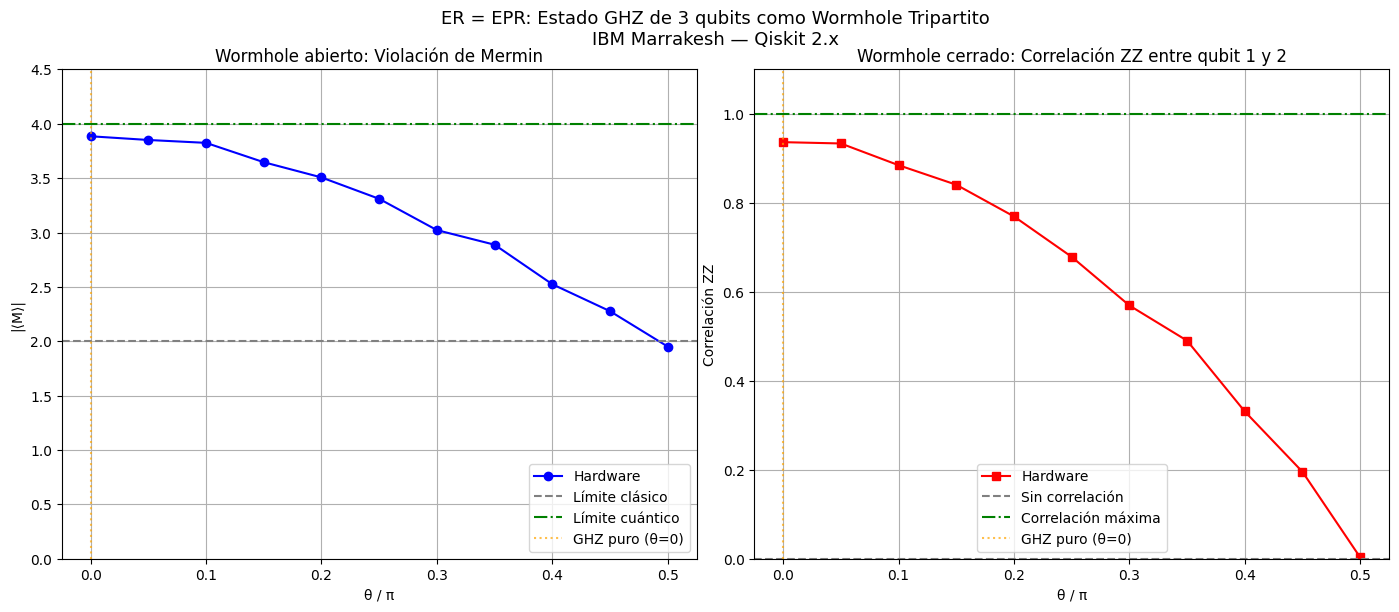

Máximo |⟨M⟩| observado:           3.885  (límite clásico: 2, cuántico: 4)
|⟨M⟩| en θ=0 (GHZ puro):          3.885
Correlación ZZ en θ=0 (GHZ puro):  0.937
Correlación ZZ en θ=π/2:           0.003
Correlación ZZ promedio:            0.603


In [5]:
import numpy as np
import matplotlib.pyplot as plt

result_base = job_base.result()
mermin_raw = result_base[0].data.evs.flatten()
mermin_values = np.abs(mermin_raw)

result_cut1 = job_cut1.result()
bit_array = result_cut1[0].data.c

correlacion_12 = []
for i in range(11):
    counts = bit_array.get_counts(i)
    total = sum(counts.values())
    p000 = counts.get('000', 0) / total
    p001 = counts.get('001', 0) / total
    p010 = counts.get('010', 0) / total
    p011 = counts.get('011', 0) / total
    p100 = counts.get('100', 0) / total
    p101 = counts.get('101', 0) / total
    p110 = counts.get('110', 0) / total
    p111 = counts.get('111', 0) / total

    czz_12 = abs((p000 + p100 + p011 + p111) - (p001 + p101 + p010 + p110))
    correlacion_12.append(czz_12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('ER = EPR: Estado GHZ de 3 qubits como Wormhole Tripartito\n'
             'IBM Marrakesh — Qiskit 2.x', fontsize=13)
plt.tight_layout()
plt.subplots_adjust(top=0.88)

ax1.plot(phases/np.pi, mermin_values, 'o-', color='blue', label='Hardware')
ax1.axhline(2, color='gray', ls='--', label='Límite clásico')
ax1.axhline(4, color='green', ls='-.', label='Límite cuántico')
ax1.axvline(0, color='orange', ls=':', alpha=0.7, label='GHZ puro (θ=0)')
ax1.set_ylim(0, 4.5)
ax1.set_title('Wormhole abierto: Violación de Mermin')
ax1.set_xlabel('θ / π')
ax1.set_ylabel('|⟨M⟩|')
ax1.legend()
ax1.grid(True)

ax2.plot(phases/np.pi, correlacion_12, 's-', color='red', label='Hardware')
ax2.axhline(0, color='gray', ls='--', label='Sin correlación')
ax2.axhline(1, color='green', ls='-.', label='Correlación máxima')
ax2.axvline(0, color='orange', ls=':', alpha=0.7, label='GHZ puro (θ=0)')
ax2.set_ylim(0, 1.1)
ax2.set_title('Wormhole cerrado: Correlación ZZ entre qubit 1 y 2')
ax2.set_xlabel('θ / π')
ax2.set_ylabel('Correlación ZZ')
ax2.legend()
ax2.grid(True)

plt.show()

print(f"Máximo |⟨M⟩| observado:           {max(mermin_values):.3f}  (límite clásico: 2, cuántico: 4)")
print(f"|⟨M⟩| en θ=0 (GHZ puro):          {mermin_values[0]:.3f}")
print(f"Correlación ZZ en θ=0 (GHZ puro):  {correlacion_12[0]:.3f}")
print(f"Correlación ZZ en θ=π/2:           {correlacion_12[-1]:.3f}")
print(f"Correlación ZZ promedio:            {np.mean(correlacion_12):.3f}")
